# Python for Chemists — Day 6
## EIS made easy: Nyquist plot, equivalent-circuit fitting & in-situ EIS in Python ⚡🔬

*Requested in the comments on Day 5 — thank you, Sareer Ahmad (EIS fitting, Rs and Rct) and Dr. Dhanasekaran Thangavelu (in-situ EIS code)!*

**What you will learn today**
1. Plot a Nyquist plot correctly (equal axes!)
2. Read **Rs** and **Rct** quickly *without* any fitting
3. Fit an **equivalent circuit** (Randles + CPE + Warburg) with one function
4. Get the fitted values **with ± errors** and a fit-quality number
5. **In-situ EIS:** fit 10 spectra in one loop and track **Rs, Rct and C_dl vs. potential**
6. Use the same code for **your own data** (any instrument, any sign convention)

Only standard libraries are used: `numpy`, `pandas`, `matplotlib`, `scipy` — nothing extra to install.

> *The CSV files used here are sample (simulated) data for a pseudocapacitive oxide electrode, made only for teaching. Replace them with your own measurements.*

## The idea in simple words 🏠

EIS sends a small AC signal at many frequencies (fast → slow) and measures how the electrode "resists" at each one.
Think of electrons and ions travelling to your electrode:

| Circuit part | Symbol | Simple meaning | Where you see it in Nyquist |
|---|---|---|---|
| Solution resistance | **Rs** | The *road* — electrolyte + contacts | Where the curve starts on the x-axis (high frequency) |
| Charge-transfer resistance | **Rct** | The *door* — how hard it is for charge to cross the electrode surface | **Diameter of the semicircle** (smaller = faster kinetics ✅) |
| Constant phase element | **CPE (Q, n)** | A "not-perfect" capacitor (rough, porous surface) | Makes the semicircle look *squashed*; n = 1 is a perfect capacitor |
| Warburg element | **W (σ)** | The *traffic jam* — slow ion diffusion | The ~45° straight tail at low frequency |

**Circuit used (Randles + CPE):**  `Rs + [ CPE ∥ (Rct + W) ]`

$$Z = R_s + \frac{1}{\;Q(j\omega)^n + \dfrac{1}{R_{ct} + \sigma(1-j)\,\omega^{-1/2}}\;}$$

## Step 1 — Load the data and draw the Nyquist plot

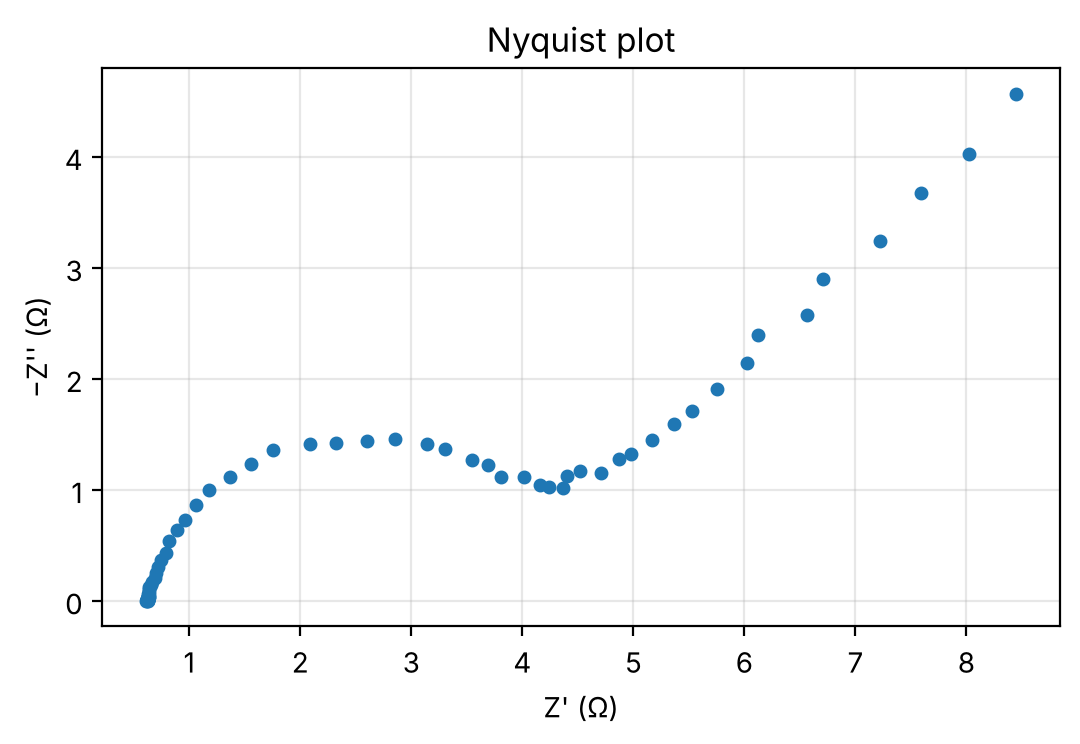

71 points, from 100,000 Hz down to 0.01 Hz


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

df = pd.read_csv("EIS_single_spectrum.csv")   # columns: freq_Hz, Z_real_ohm, minus_Z_imag_ohm
f    = df["freq_Hz"].to_numpy()
Zre  = df["Z_real_ohm"].to_numpy()
mZim = df["minus_Z_imag_ohm"].to_numpy()       # -Z'' (positive in the usual Nyquist plot)
Z    = Zre - 1j * mZim                          # complex impedance Z = Z' + jZ''

plt.figure(figsize=(5.5, 5))
plt.plot(Zre, mZim, "o", ms=4)
plt.xlabel("Z' (Ω)"); plt.ylabel("−Z'' (Ω)")
plt.title("Nyquist plot")
plt.gca().set_aspect("equal")                  # IMPORTANT: same scale on both axes
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"{len(f)} points, from {f.max():,.0f} Hz down to {f.min()} Hz")

> 💡 **Always use equal axes** (`set_aspect("equal")`). Without it a semicircle looks like an oval and your eye reads the wrong Rct.

## Step 2 — Quick estimate (no fitting) 👀
- **Rs** ≈ the real part at the highest frequency
- The top of the semicircle is at Z' ≈ Rs + Rct/2, so **Rct ≈ 2 × (Z' at the semicircle top − Rs)**

These quick numbers are also used as the *starting guess* for the fit.

In [2]:
def quick_estimate(f, Z):
    Zre, mZim = Z.real, -Z.imag
    Rs0 = Zre[np.argmax(f)]                          # highest frequency point
    hf = f > 1                                       # semicircle region (above 1 Hz)
    top = np.argmax(np.where(hf, mZim, -np.inf))     # top of the semicircle
    Rct0 = max(2 * (Zre[top] - Rs0), 1e-3)
    f_top = f[top]
    return Rs0, Rct0, f_top

Rs0, Rct0, f_top = quick_estimate(f, Z)
print(f"Quick estimate:  Rs ≈ {Rs0:.3f} Ω   Rct ≈ {Rct0:.3f} Ω   (semicircle top at {f_top:.1f} Hz)")

Quick estimate:  Rs ≈ 0.625 Ω   Rct ≈ 4.462 Ω   (semicircle top at 4.0 Hz)


## Step 3 — The circuit model in ONE function

In [3]:
def randles_cpe_w(f, Rs, Rct, Q, n, sigma):
    # Rs + [CPE || (Rct + Warburg)]
    w = 2 * np.pi * f
    Z_cpe = 1 / (Q * (1j * w) ** n)
    Z_w = sigma * (1 - 1j) / np.sqrt(w)
    return Rs + 1 / (1 / Z_cpe + 1 / (Rct + Z_w))

## Step 4 — Fit the circuit (with ± errors) 🎯
We fit real and imaginary parts **together**, each divided by |Z| ("modulus weighting") so the small high-frequency points count as much as the big low-frequency ones.
The ± values come from the fit's covariance matrix (standard error).

In [4]:
NAMES = ["Rs (Ω)", "Rct (Ω)", "Q (F·s^(n-1))", "n", "σ (Ω·s^-½)"]

def fit_eis(f, Z, guess=None):
    if guess is None:                                    # automatic starting guess
        Rs0, Rct0, f_top = quick_estimate(f, Z)
        guess = [Rs0, Rct0, 1 / (2 * np.pi * f_top * Rct0), 0.85, 1.0]

    def residuals(p):
        d = (randles_cpe_w(f, *p) - Z) / np.abs(Z)
        return np.concatenate([d.real, d.imag])

    lower = [0, 0, 1e-9, 0.4, 0]
    upper = [np.inf, np.inf, 10, 1.0, np.inf]
    res = least_squares(residuals, guess, bounds=(lower, upper), x_scale="jac")

    dof = 2 * len(f) - len(guess)
    s2 = np.sum(res.fun ** 2) / dof                      # "chi-square per point"
    cov = np.linalg.pinv(res.jac.T @ res.jac) * s2
    err = np.sqrt(np.diag(cov))
    return res.x, err, s2

p, err, chi2 = fit_eis(f, Z)

table = pd.DataFrame({"Parameter": NAMES, "Value": p, "± Error": err,
                      "Error (%)": 100 * err / p}).round(5)
print(table.to_string(index=False))
print(f"\nFit quality (weighted χ² per point) = {chi2:.2e}   → below ~1e-3 is a good fit")

    Parameter   Value  ± Error  Error (%)
       Rs (Ω) 0.62106  0.00096    0.15458
      Rct (Ω) 3.40069  0.01278    0.37580
Q (F·s^(n-1)) 0.01177  0.00013    1.14454
            n 0.86361  0.00223    0.25770
   σ (Ω·s^-½) 1.14305  0.00600    0.52479

Fit quality (weighted χ² per point) = 6.29e-05   → below ~1e-3 is a good fit


### Bonus: true double-layer capacitance from the CPE (Brug formula)
Q is not in farads when n < 1. The **effective C_dl** (in F) is:
$$C_{dl} = Q^{1/n}\left(\frac{1}{R_s}+\frac{1}{R_{ct}}\right)^{(n-1)/n}$$

In [5]:
def cdl_brug(Rs, Rct, Q, n):
    return Q ** (1 / n) * (1 / Rs + 1 / Rct) ** ((n - 1) / n)

Rs, Rct, Q, n, sigma = p
print(f"Effective double-layer capacitance C_dl = {cdl_brug(Rs, Rct, Q, n)*1000:.2f} mF")

Effective double-layer capacitance C_dl = 5.27 mF


## Step 5 — Check the fit by eye (Nyquist + Bode) ✅

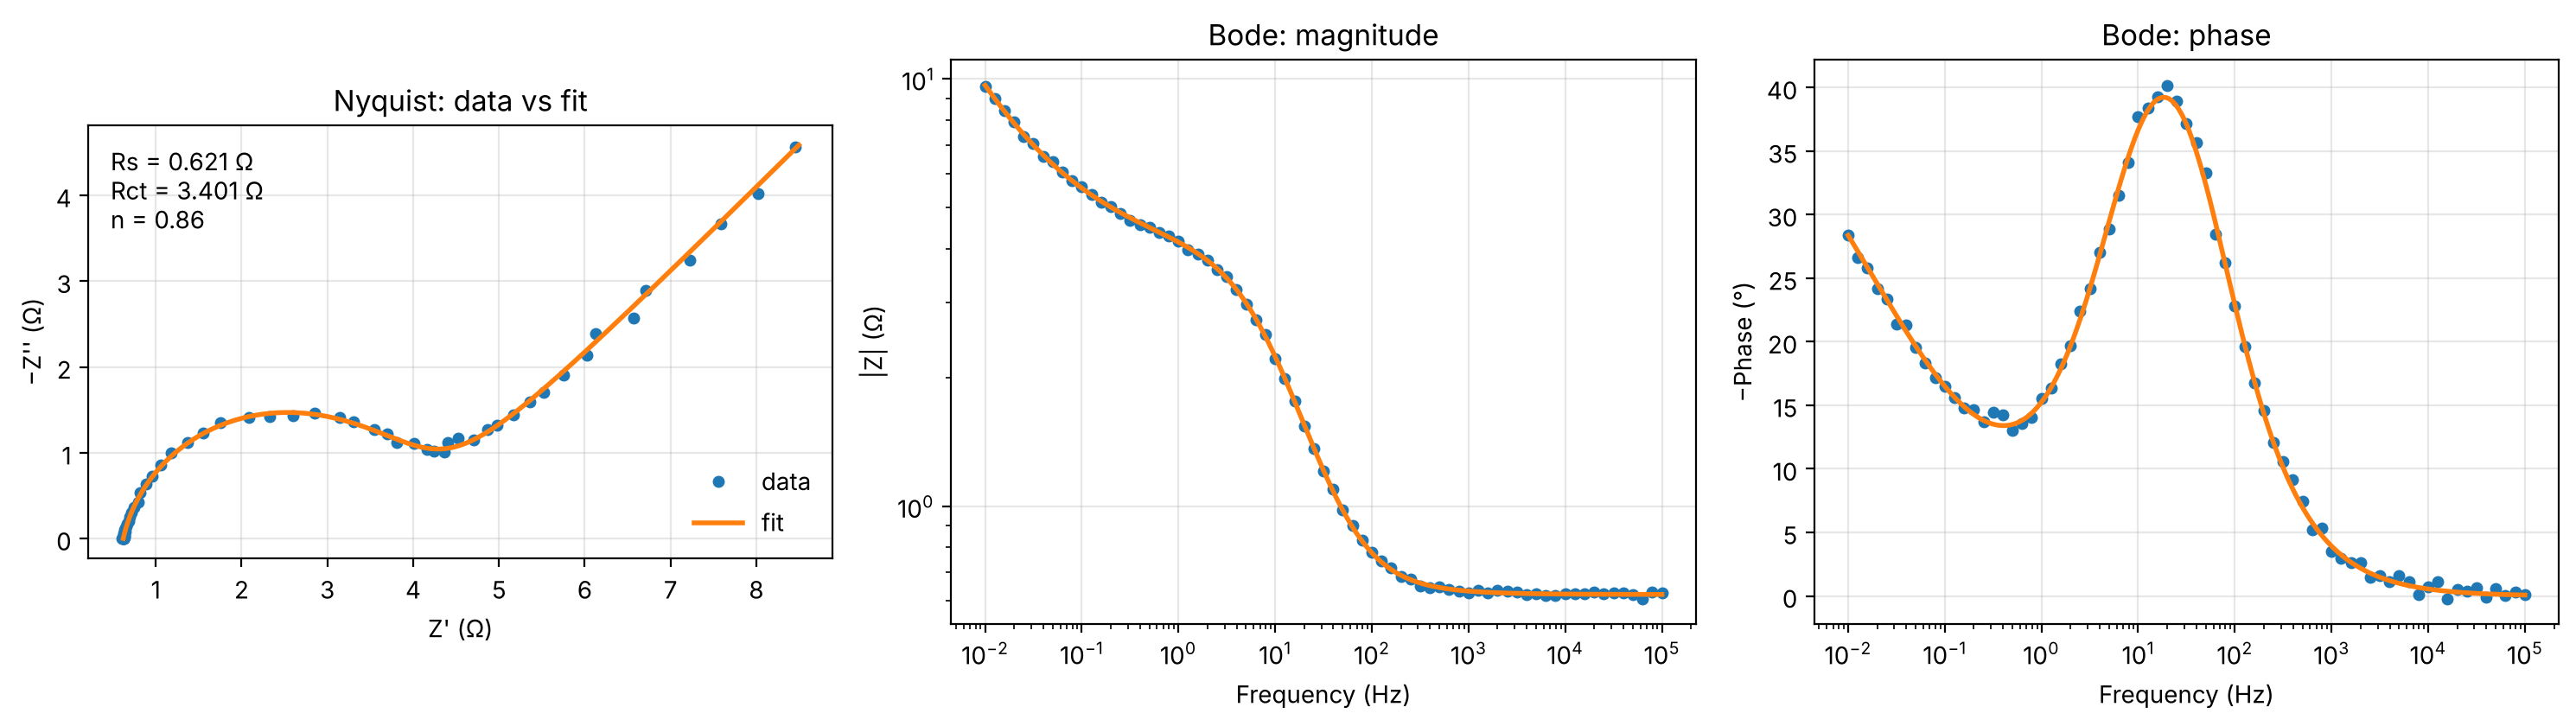

In [6]:
f_smooth = np.logspace(np.log10(f.max()), np.log10(f.min()), 400)
Zfit = randles_cpe_w(f_smooth, *p)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].plot(Zre, mZim, "o", ms=4, label="data")
ax[0].plot(Zfit.real, -Zfit.imag, "-", lw=2, label="fit")
ax[0].set_aspect("equal"); ax[0].set_xlabel("Z' (Ω)"); ax[0].set_ylabel("−Z'' (Ω)")
ax[0].set_title("Nyquist: data vs fit"); ax[0].legend(frameon=False)
ax[0].text(0.03, 0.95, f"Rs = {Rs:.3f} Ω\nRct = {Rct:.3f} Ω\nn = {n:.2f}",
           transform=ax[0].transAxes, va="top")

ax[1].loglog(f, np.abs(Z), "o", ms=4); ax[1].loglog(f_smooth, np.abs(Zfit), "-", lw=2)
ax[1].set_xlabel("Frequency (Hz)"); ax[1].set_ylabel("|Z| (Ω)"); ax[1].set_title("Bode: magnitude")

ax[2].semilogx(f, -np.angle(Z, deg=True), "o", ms=4); ax[2].semilogx(f_smooth, -np.angle(Zfit, deg=True), "-", lw=2)
ax[2].set_xlabel("Frequency (Hz)"); ax[2].set_ylabel("−Phase (°)"); ax[2].set_title("Bode: phase")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("Day06_EIS_fit.png", dpi=300); plt.show()

## Step 6 — In-situ EIS: fit MANY spectra in one loop 🔁
In-situ EIS = recording a spectrum at **each potential** (or each time / cycle / temperature) while the electrode is working.
Fitting them one by one in software takes hours. In Python it is one loop.

Our file has 10 spectra recorded from 0.00 V to 0.45 V. The only thing that changes is the column name `potential_V`.

In [7]:
insitu = pd.read_csv("EIS_insitu_potentials.csv")   # potential_V, freq_Hz, Z_real_ohm, minus_Z_imag_ohm
STEP_COLUMN = "potential_V"     # 👈 change to "time_min", "cycle", "temperature_C" ... for your own data

results, spectra = [], {}
guess = None
for value, g in insitu.groupby(STEP_COLUMN):
    fi = g["freq_Hz"].to_numpy()
    Zi = g["Z_real_ohm"].to_numpy() - 1j * g["minus_Z_imag_ohm"].to_numpy()
    pi, ei, chi = fit_eis(fi, Zi, guess)
    guess = pi                                          # use the last result as the next start (more stable)
    spectra[value] = (fi, Zi, pi)
    results.append({STEP_COLUMN: value,
                    "Rs (Ω)": pi[0], "Rs err": ei[0],
                    "Rct (Ω)": pi[1], "Rct err": ei[1],
                    "n": pi[3], "C_dl (mF)": 1000 * cdl_brug(*pi[:4]),
                    "χ²": chi})

res = pd.DataFrame(results).round(4)
res.to_csv("Day06_insitu_fit_results.csv", index=False)
res

,potential_V,Rs (Ω),Rs err,Rct (Ω),Rct err,n,C_dl (mF),χ²
0,0.00,0.6001,0.0009,5.5894,0.0172,0.8602,4.2835,0.0001
1,0.05,0.6034,0.0010,5.4931,0.0187,0.8595,4.4197,0.0001
2,0.10,0.6077,0.0009,5.2125,0.0167,0.8620,4.6700,0.0001
3,0.15,0.6112,0.0008,4.4664,0.0138,0.8616,5.2651,0.0001
4,0.20,0.6161,0.0010,3.2051,0.0133,0.8580,6.1320,0.0001
5,0.25,0.6193,0.0009,1.7585,0.0085,0.8544,6.7842,0.0001
6,0.30,0.6257,0.0011,1.1022,0.0079,0.8684,7.1033,0.0001
7,0.35,0.6269,0.0010,1.7538,0.0093,0.8581,6.7842,0.0001
8,0.40,0.6321,0.0009,3.1945,0.0128,0.8564,6.1198,0.0001
9,0.45,0.6368,0.0011,4.5076,0.0185,0.8590,5.2983,0.0001


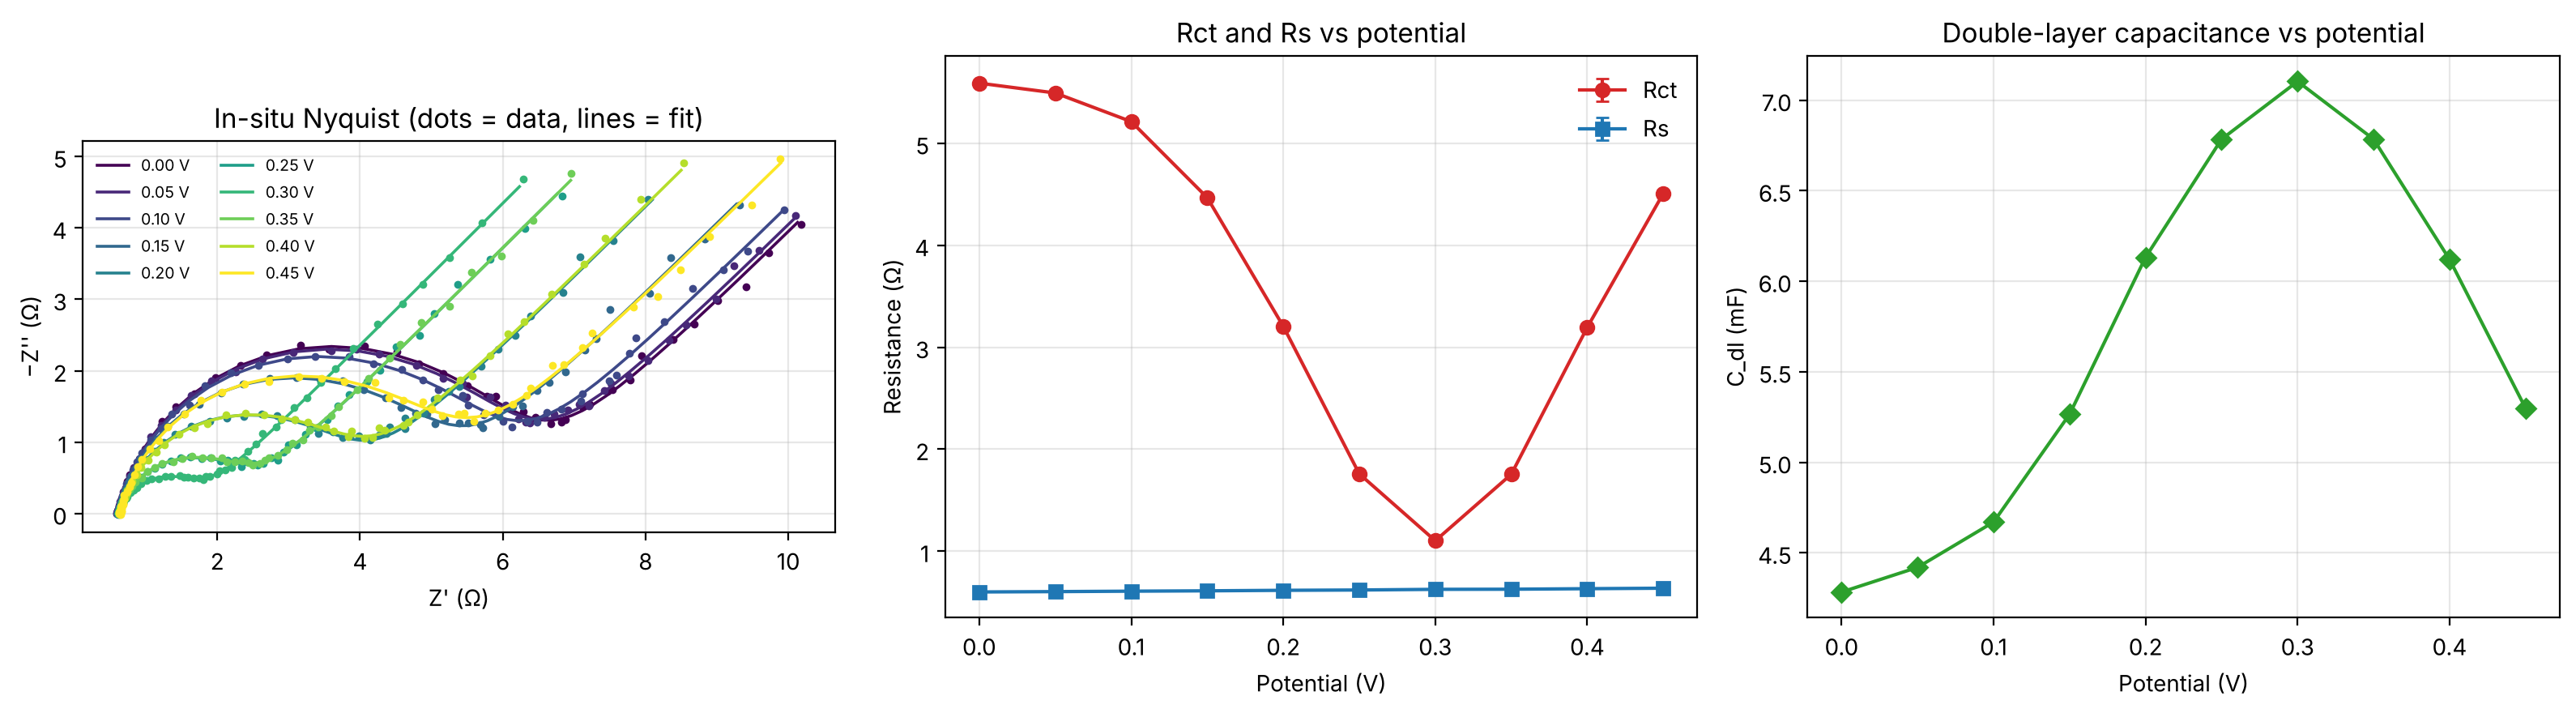

Fastest charge transfer (lowest Rct = 1.10 Ω) at 0.30 V → close to the redox peak you would see in CV.


In [8]:
cmap = plt.cm.viridis
vals = list(spectra)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

for k, v in enumerate(vals):
    fi, Zi, pi = spectra[v]
    c = cmap(k / (len(vals) - 1))
    ax[0].plot(Zi.real, -Zi.imag, "o", ms=2.5, color=c)
    Zf = randles_cpe_w(fi, *pi)
    ax[0].plot(Zf.real, -Zf.imag, "-", lw=1.3, color=c, label=f"{v:.2f} V")
ax[0].set_aspect("equal"); ax[0].set_xlabel("Z' (Ω)"); ax[0].set_ylabel("−Z'' (Ω)")
ax[0].set_title("In-situ Nyquist (dots = data, lines = fit)"); ax[0].legend(fontsize=7, ncol=2, frameon=False)

ax[1].errorbar(res[STEP_COLUMN], res["Rct (Ω)"], yerr=res["Rct err"], fmt="o-", color="tab:red", capsize=3, label="Rct")
ax[1].errorbar(res[STEP_COLUMN], res["Rs (Ω)"], yerr=res["Rs err"], fmt="s-", color="tab:blue", capsize=3, label="Rs")
ax[1].set_xlabel("Potential (V)"); ax[1].set_ylabel("Resistance (Ω)")
ax[1].set_title("Rct and Rs vs potential"); ax[1].legend(frameon=False)

ax[2].plot(res[STEP_COLUMN], res["C_dl (mF)"], "D-", color="tab:green")
ax[2].set_xlabel("Potential (V)"); ax[2].set_ylabel("C_dl (mF)"); ax[2].set_title("Double-layer capacitance vs potential")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("Day06_insitu_EIS.png", dpi=300); plt.show()

best = res.loc[res["Rct (Ω)"].idxmin()]
print(f"Fastest charge transfer (lowest Rct = {best['Rct (Ω)']:.2f} Ω) at {best[STEP_COLUMN]:.2f} V "
      "→ close to the redox peak you would see in CV.")

**How to read this:** Rct is lowest where the redox reaction is easiest (near the CV peak), and rises again on both sides. Rs barely changes — so the electrolyte/contacts are stable. That is exactly the kind of story reviewers like to see from in-situ EIS.

## Step 7 — Use YOUR own data 📂
Instruments export EIS in different ways. This small helper makes any file ready:

In [9]:
def load_my_eis(path, freq_col, real_col, imag_col):
    d = pd.read_csv(path)
    f = d[freq_col].to_numpy(float)
    re = d[real_col].to_numpy(float)
    im = d[imag_col].to_numpy(float)
    if np.median(im) > 0:          # file already gives -Z'' (positive) → convert back to Z''
        im = -im
    keep = im < 0                  # drop inductive points (Z'' > 0) at very high frequency
    return f[keep], re[keep] + 1j * im[keep]

# Example (change the file and column names to match your instrument):
# f_my, Z_my = load_my_eis("my_sample.csv", "Freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm")
# p_my, err_my, chi_my = fit_eis(f_my, Z_my)

## ✅ Tips before you put EIS in a paper
1. **Equal axes** on every Nyquist plot.
2. **Show data + fit together**, and report the circuit, the values **with errors** and χ².
3. If **n < 0.7**, the CPE is far from a capacitor — reconsider the circuit.
4. If an error is **larger than the value**, that element is not needed (over-fitting) — remove it.
5. Use **C_dl from the Brug formula**, not Q, when you talk about capacitance.
6. For a no-tail spectrum (blocking electrode), remove the Warburg part: set `sigma` to 0 and its bounds to (0, 1e-12).
7. For two semicircles (e.g. SEI + charge transfer), add a second `R ∥ CPE` block in the function.

**Next (Day 7):** CV curves — b-value analysis to separate capacitive vs diffusion-controlled charge (tell me in the comments if you want something else!)

*Muhammad Amjad — Python for Chemists series · github.com/muhammadamjad9200/Python-for-chemists*